# Tuning initial α/β: `resolve_initial_α_β` (with T active-variable handling)

Demonstrates `resolve_initial_α_β` (`src/tune_regularization.jl`): given `rechp.α_init`/`β_init`
set to `:auto`, it samples a single random object/noise draw (held fixed throughout), then runs an
NLopt search in log-space to find the `α`/`β` that minimize that one object's reconstruction error
-- using the exact same adjoint/Hessian machinery (`build_hessian_operator_distributed`, `minres!`)
already validated for the main outer optimization, just without the geoms-gradient or Adam update.

This re-runs `2026-10-20-tune-regularization.ipynb` on `features/active-variables-T`: that
notebook predates this branch's work, so its sweep silently computed a wrong `dL_dα`/`dL_dβ`
whenever a candidate `(α, β)` happened to pin some `Tmap` pixels (T had no active-set handling at
all before this branch). `reconstruction_error_and_grad` now uses `get_free_and_active_indices`
the same way everywhere else does, so the gradient stays correct even when T pins mid-search --
and `out.history` now also tracks `n_active_T`/`n_active_z` per iteration, so that can actually be
checked directly below, rather than just assumed.

Same `php`/`imghp`/`opthp` as `scripts/endtoend_opt.jl` (`UniformlyRandomObject`,
`geoms_init_type = "monochromatic"`), except `rechp.α_init = rechp.β_init = :auto` here, since
that's the whole point of this notebook.

In [1]:
cd("../../End2EndThermalImg")
import Pkg
Pkg.activate(".")

  Activating project at `~/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg`


In [2]:
using Revise
using End2EndThermalImg
using PythonPlot
using Parameters
using Distributed
using LinearAlgebra
using Statistics

## Setup

In [3]:
@time nw = End2EndThermalImg.setup_cluster_workers()
println("nworkers = ", nworkers(), "  workers = ", workers())
println("threads per worker = ", [remotecall_fetch(Threads.nthreads, p) for p in workers()])

      From worker 2:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 2:	└   lock_file = "/Users/sophiefisher/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg/.CondaPkg/lock"
      From worker 6:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 6:	└   lock_file = "/Users/sophiefisher/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg/.CondaPkg/lock"
      From worker 5:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 5:	└   lock_file = "/Users/sophiefisher/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg/.CondaPkg/lock"
      From worker 4:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 4:	└   lock_file = "/Us

In [4]:
# Same hyperparameters as scripts/endtoend_opt.jl, except α_init/β_init = :auto (the whole point
# of this notebook) in place of literal values.
@time @everywhere begin
    php = PhysicsHyperParams(
        λlb_μm = 8.0,
        λub_μm = 12.0,
        freq_order = 20,
        focal_length_μm = 2.0e4,
        num_unit_cells = 2048,
        unit_cell_length_μm = 4.0,
        pillar_width_lb_μm = 1.8,
        pillar_width_ub_μm = 2.7,
        pillar_width_order = 160,
        pillar_height_μm = 10.0,
        pillar_material = "Si_no_absorption",
        substrate_height_μm = 300.0,
        substrate_material = "Si_no_absorption",
        nG = 1000
    )

    imghp = ImagingHyperParams(
        objN = 32,
        imgN = 128,
        binN = 3,
        sampleN = 1,
        PSF_zlb_μm = -2.1e6,
        PSF_zub_μm = -0.9e6,
        PSF_zlen = 3,
        smoothness_order = 3.0,
        object_type = UniformlyRandomObject(Tlb = 136.15, Tub = 450.15, zlb_μm = -2.0e6, zub_μm = -1.0e6, zlen = 7, php = php),
        noise_type = RelativeNoise(0.2),
        php = php
    )

    opthp = OptimizeHyperParams(
        geoms_init_type = "monochromatic",
        maxeval = 10,
        learning_rate = 1e-3,
        save_every = 3
    )

    rechp = ReconstructionHyperParams(
        object_init_type = "uniform_offset",
        T_background = 293.15,
        z_middle_μm = -1.5e6,
        algorithm = :LD_LBFGS,
        α_init = :auto,
        β_init = :auto,
        maxeval = 2000,
        xtol_rel = 0.0,
        ftol_rel = 0.0,
        ftol_abs = 0.0,
        php = php
    )

    jhp = JobHyperParams(
        php = php,
        imghp = imghp,
        opthp = opthp,
        rechp = rechp
    )
end

  0.139791 seconds (102.63 k allocations: 5.612 MiB, 44.59% compilation time)


In [5]:
@time End2EndThermalImg.compute_system_parameters(php, imghp)

[ Info: Computing system parameters
[ Info: Image pixel size = 12.0 μm


  0.497891 seconds (2.22 M allocations: 111.987 MiB, 3.01% gc time, 106.39% compilation time)


[ Info: Metasurface size = 8192.0 μm [0.8192 cm]
[ Info: NA: 0.2006


In [6]:
@time driver_plans_n2f, driver_plans_PSF = End2EndThermalImg.setup_fft_plans_distributed!(php, imghp)

  0.662677 seconds (445.00 k allocations: 413.921 MiB, 1.19% gc time, 13.02% compilation time)


(FFTW.cFFTWPlan[FFTW forward plan for 2528×2528 array of ComplexF64
(dft-rank>=2/1
  (dft-thr-vrank>=1-x2/1
    (dft-vrank>=1-x1264/1
      (dft-ct-dit/32
        (dftw-direct-32/124 "t2fv_32_neon")
        (dft-vrank>=1-x32/1
          (dft-bluestein-79/160
            (dft-ct-dit/4
              (dftw-direct-4/12 "t2fv_4_neon")
              (dft-ct-dif/4
                (dftw-directsq-4/6-x4 "q1fv_4_neon")
                (dft-vrank>=1-x4/1
                  (dft-direct-10-x4 "n1fv_10_neon"))))))))
    (dft-vrank>=1-x1264/1
      (dft-ct-dit/32
        (dftw-direct-32/124 "t2fv_32_neon")
        (dft-vrank>=1-x32/1
          (dft-bluestein-79/160
            (dft-ct-dit/4
              (dftw-direct-4/12 "t2fv_4_neon")
              (dft-ct-dif/4
                (dftw-directsq-4/6-x4 "q1fv_4_neon")
                (dft-vrank>=1-x4/1
                  (dft-direct-10-x4 "n1fv_10_neon")))))))))
  (dft-thr-vrank>=1-x2/1
    (dft-buffered-2528-x8/1264-6
      (dft-vrank>=1-x8/1
        (d

In [7]:
@time freqs = End2EndThermalImg.get_freq_chebpoints(php)
@time n2f_kernels = End2EndThermalImg.compute_and_broadcast(:n2f_kernels, End2EndThermalImg.get_n2f_kernels, freqs, driver_plans_n2f, php, imghp);

  0.165927 seconds (1.09 M allocations: 53.017 MiB, 4.37% gc time, 99.98% compilation time)
  7.115646 seconds (745.75 k allocations: 4.035 GiB, 6.06% gc time, 4.96% compilation time)


In [8]:
@time @everywhere begin
    surrogates = End2EndThermalImg.load_surrogate_models(php);
    PSF_zcoords = End2EndThermalImg.get_PSF_zcoords(imghp)
    weights = End2EndThermalImg.get_clenshaw_curtis_quadrature_weights(php)
end

# Driver-only (not @everywhere): nothing in the package reads a worker's own resident `geoms` --
# it's always passed as an explicit argument. With geoms_init_type == "monochromatic", running
# this on every worker would mean several processes concurrently hitting inversedesign/.
geoms = End2EndThermalImg.initialize_geoms(php, opthp; imghp = imghp)

  2.419666 seconds (7.26 M allocations: 400.442 MiB, 12.12% gc time, 99.50% compilation time: <1% of which was recompilation)


[ Info: Folder already exists: inversedesign
┌ Info: Reusing existing monochromatic lens design
└   run_folder = "inversedesign/monochromatic_lens_2026-10-20T17:24:58.885"


2048×2048 Matrix{Float64}:
 0.21514   0.227641  0.233045  0.239982  …  0.2135    0.211347  0.207674
 0.227641  0.233052  0.239998  0.249827     0.222908  0.213496  0.21134
 0.233045  0.239998  0.249839  0.266236     0.22831   0.222893  0.213488
 0.239982  0.249827  0.266236  0.281128     0.233872  0.228294  0.222868
 0.24979   0.266207  0.281125  0.281166     0.241125  0.233846  0.228269
 0.266147  0.28111   0.281166  0.201874  …  0.251569  0.241082  0.23381
 0.281064  0.281166  0.201844  0.208554     0.268063  0.251463  0.241025
 0.281166  0.201798  0.208536  0.211806     0.281246  0.267955  0.251323
 0.201738  0.208509  0.211794  0.213834     0.195434  0.281165  0.267838
 0.208474  0.211777  0.213823  0.223929     0.202866  0.195375  0.281164
 0.211755  0.213808  0.223871  0.22904   …  0.209073  0.202798  0.195279
 0.213789  0.223797  0.228995  0.234808     0.21206   0.20902   0.202715
 0.223708  0.22894   0.234738  0.242321     0.214023  0.212031  0.208956
 ⋮                        

## `geoms` (monochromatic lens)

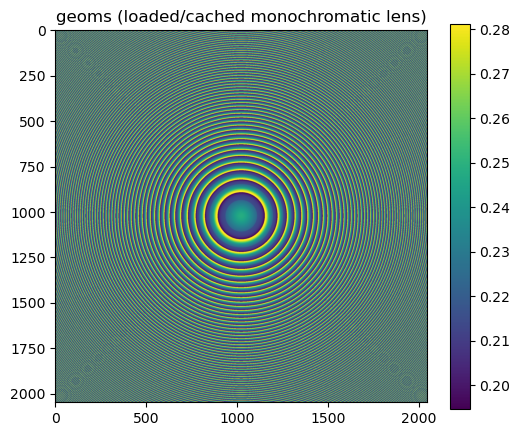

In [9]:
fig, ax = subplots(figsize=(6, 5))
im = ax.imshow(geoms)
ax.set_title("geoms (loaded/cached monochromatic lens)")
fig.colorbar(im, ax=ax)
fig;

In [10]:
@time End2EndThermalImg.assign_shard_indices!()
@time End2EndThermalImg.init_resident_incidents!(freqs, PSF_zcoords, php)

  0.025049 seconds (390 allocations: 20.305 KiB, 9.15% compilation time)
  2.023320 seconds (181.66 k allocations: 9.068 MiB, 1.80% compilation time)


## Choose `PSF_scale`

In [11]:
reference_scale = 1.0
End2EndThermalImg.update_geoms_and_fftPSFs!(geoms, freqs, php, imghp, reference_scale)
object_reference = End2EndThermalImg.get_object(imghp)
image_reference = End2EndThermalImg.make_image_from_3D_distributed(object_reference, weights, php, imghp)
PSF_scale = End2EndThermalImg.choose_PSF_scale(image_reference, reference_scale; target_mean = 1.0)
println("PSF_scale = ", PSF_scale, "  (mean(image) at reference_scale=1.0 was ", mean(image_reference), ")")
End2EndThermalImg.update_geoms_and_fftPSFs!(geoms, freqs, php, imghp, PSF_scale);

PSF_scale = 4.7703131442601375e13  (mean(image) at reference_scale=1.0 was 2.096298439449927e-14)


## Resolve `α_init`/`β_init`

Both are `:auto`, so this samples one random object/noise draw (held fixed) and jointly searches
log-space for the `(α, β)` minimizing that object's reconstruction error.

In [12]:
α_start = 1e-7
β_start = 1e-7
out = End2EndThermalImg.resolve_initial_α_β(
    rechp, geoms, freqs, weights, driver_plans_PSF, PSF_zcoords, jhp, PSF_scale;
    α_start = α_start, β_start = β_start, verbose = true
)

println("\nresolved α = ", out.α)
println("resolved β = ", out.β)
println("return_value = ", out.return_value)
println("iterations = ", length(out.history))

┌ Info: resolve_initial_α_β iteration 1
│   α = 9.999999999999994e-8
│   β = 9.999999999999994e-8
│   L = 0.1579423803654484
│   n_active_T = 0
└   n_active_z = 0
┌ Info: resolve_initial_α_β iteration 2
│   α = 1.0076306345489169e-7
│   β = 1.0000000001347325e-7
│   L = 0.15788507945142718
│   n_active_T = 0
└   n_active_z = 0
┌ Info: resolve_initial_α_β iteration 3
│   α = 1.5735978615003136e-7
│   β = 1.0000000080354953e-7
│   L = 0.15435444366931853
│   n_active_T = 0
└   n_active_z = 0
┌ Info: resolve_initial_α_β iteration 4
│   α = 0.0002739740296813946
│   β = 1.000000140297486e-7
│   L = 0.15501477703962924
│   n_active_T = 0
└   n_active_z = 0
┌ Info: resolve_initial_α_β iteration 5
│   α = 1.2159617576960918e-5
│   β = 1.0000001393386723e-7
│   L = 0.13380731184036648
│   n_active_T = 0
└   n_active_z = 0
┌ Info: resolve_initial_α_β iteration 6
│   α = 5.6288165089851785e-6
│   β = 1.000000139101589e-7
│   L = 0.1318941824512041
│   n_active_T = 0
└   n_active_z = 0
┌ Info: re


resolved α = 5.076692050516811e-6
resolved β = 9.999999554327385e-8
return_value = FAILURE
iterations = 30


## Optimization history: α, β, L

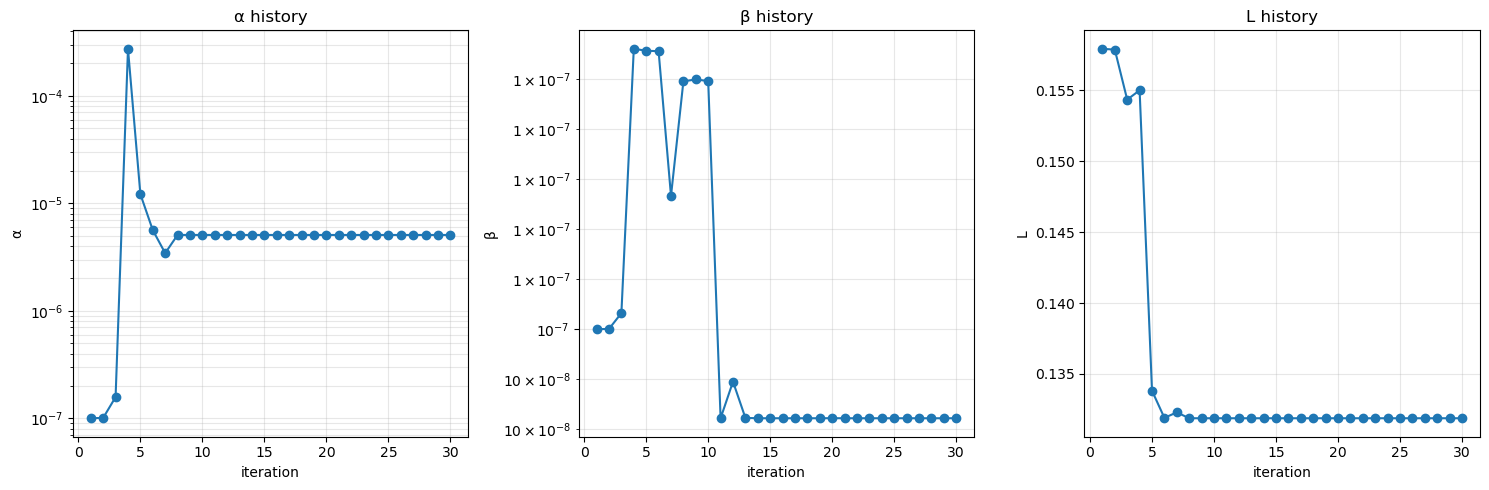

In [13]:
iterations_hist = [h.iteration for h in out.history]
α_hist = [h.α for h in out.history]
β_hist = [h.β for h in out.history]
L_hist = [h.L for h in out.history]

fig, axes = subplots(1, 3; figsize=(15, 5))

axes[0].semilogy(iterations_hist, α_hist, marker="o")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("α")
axes[0].set_title("α history")
axes[0].grid(true, which="both", alpha=0.3)

axes[1].semilogy(iterations_hist, β_hist, marker="o")
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("β")
axes[1].set_title("β history")
axes[1].grid(true, which="both", alpha=0.3)

axes[2].plot(iterations_hist, L_hist, marker="o")
axes[2].set_xlabel("iteration")
axes[2].set_ylabel("L")
axes[2].set_title("L history")
axes[2].grid(true, alpha=0.3)

fig.tight_layout()
fig;

## Active (pinned) pixels during the search

`n_active_T`/`n_active_z` per iteration -- how many `Tmap`/`zmap` pixels were pinned at their
bound in the candidate reconstruction evaluated at that iteration's `(α, β)`. This is the thing
that was invisible before this branch's work: a nonzero `n_active_T` here means that iteration's
`dL_dα`/`dL_dβ` depended on the (now correct) T active-set handling, not just z's.

max n_active_T over the search = 0 / 1024
max n_active_z over the search = 0 / 1024


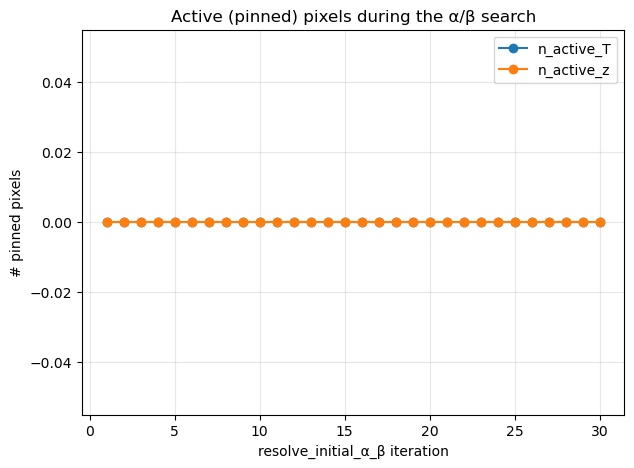

In [14]:
iterations = [h.iteration for h in out.history]
n_active_T_hist = [h.n_active_T for h in out.history]
n_active_z_hist = [h.n_active_z for h in out.history]

println("max n_active_T over the search = ", maximum(n_active_T_hist), " / ", imghp.objN^2)
println("max n_active_z over the search = ", maximum(n_active_z_hist), " / ", imghp.objN^2)

fig, ax = subplots(figsize=(7, 5))
ax.plot(iterations, n_active_T_hist, marker="o", label="n_active_T")
ax.plot(iterations, n_active_z_hist, marker="o", label="n_active_z")
ax.set_xlabel("resolve_initial_α_β iteration")
ax.set_ylabel("# pinned pixels")
ax.set_title("Active (pinned) pixels during the α/β search")
ax.legend()
ax.grid(true, alpha=0.3)
fig;

## Reconstruction of the sampled object at the initial α/β (before tuning)

Same fixed object/noise draw (`out.object`/`out.noise`), but reconstructed at the search's starting
point (`α_start`, `β_start`) instead of the resolved values -- for comparison against the tuned
result below.

In [18]:
r_init = End2EndThermalImg.reconstruction_error_and_grad(
    out.object, out.noise, α_start, β_start, freqs, weights, driver_plans_PSF, PSF_zcoords, jhp
)
object_opt_init = r_init.object_opt

# signed relative error, as a percentage of the true value -- safe here since neither Tmap (>=
# Tlb > 0) nor zmap (bounded away from 0 by PSF_zlb/PSF_zub) ever approaches zero.
error_T_init = 100 .* (object_opt_init.Tmap .- out.object.Tmap) ./ out.object.Tmap
error_z_init = 100 .* (object_opt_init.zmap .- out.object.zmap) ./ out.object.zmap

fig, axes = subplots(2, 3; figsize=(15, 10))

vlims_T = extrema(vcat(vec(out.object.Tmap), vec(object_opt_init.Tmap)))
im00 = axes[0,0].imshow(out.object.Tmap; vmin=vlims_T[1], vmax=vlims_T[2])
axes[0,0].set_title("object.Tmap (true)")
fig.colorbar(im00, ax=axes[0,0])

im01 = axes[0,1].imshow(object_opt_init.Tmap; vmin=vlims_T[1], vmax=vlims_T[2])
axes[0,1].set_title("object_opt.Tmap (reconstructed)")
fig.colorbar(im01, ax=axes[0,1])

elim_T = maximum(abs, error_T_init)
im02 = axes[0,2].imshow(error_T_init; cmap="RdBu", vmin=-elim_T, vmax=elim_T)
axes[0,2].set_title("relative error (%)")
fig.colorbar(im02, ax=axes[0,2], label="%")

vlims_z = extrema(vcat(vec(out.object.zmap), vec(object_opt_init.zmap)))
im10 = axes[1,0].imshow(out.object.zmap; vmin=vlims_z[1], vmax=vlims_z[2])
axes[1,0].set_title("object.zmap (true)")
fig.colorbar(im10, ax=axes[1,0])

im11 = axes[1,1].imshow(object_opt_init.zmap; vmin=vlims_z[1], vmax=vlims_z[2])
axes[1,1].set_title("object_opt.zmap (reconstructed)")
fig.colorbar(im11, ax=axes[1,1])

elim_z = maximum(abs, error_z_init)
im12 = axes[1,2].imshow(error_z_init; cmap="RdBu", vmin=-elim_z, vmax=elim_z)
axes[1,2].set_title("relative error (%)")
fig.colorbar(im12, ax=axes[1,2], label="%")

for ax in axes.flat
    ax.axis("off")
end
fig.suptitle("α = $(α_start), β = $(β_start)  (initial, before tuning).  n_active_T=$(r_init.n_active_T), n_active_z=$(r_init.n_active_z)")
fig.tight_layout()
fig;

LoadError: UndefRefError: access to undefined reference

## Reconstruction of the sampled object at the resolved `α`/`β`

`out.object`/`out.object_opt` are the fixed object the sweep evaluated every candidate against, and
its reconstruction at the final resolved `(α, β)` (a fresh evaluation, not reused from partway
through the search, so it's guaranteed to correspond exactly to `out.α`/`out.β`).

In [ ]:
object = out.object
object_opt = out.object_opt

# signed relative error, as a percentage of the true value -- safe here since neither Tmap (>=
# Tlb > 0) nor zmap (bounded away from 0 by PSF_zlb/PSF_zub) ever approaches zero.
error_T = 100 .* (object_opt.Tmap .- object.Tmap) ./ object.Tmap
error_z = 100 .* (object_opt.zmap .- object.zmap) ./ object.zmap

fig, axes = subplots(2, 3; figsize=(15, 10))

vlims_T = extrema(vcat(vec(object.Tmap), vec(object_opt.Tmap)))
im00 = axes[0,0].imshow(object.Tmap; vmin=vlims_T[1], vmax=vlims_T[2])
axes[0,0].set_title("object.Tmap (true)")
fig.colorbar(im00, ax=axes[0,0])

im01 = axes[0,1].imshow(object_opt.Tmap; vmin=vlims_T[1], vmax=vlims_T[2])
axes[0,1].set_title("object_opt.Tmap (reconstructed)")
fig.colorbar(im01, ax=axes[0,1])

elim_T = maximum(abs, error_T)
im02 = axes[0,2].imshow(error_T; cmap="RdBu", vmin=-elim_T, vmax=elim_T)
axes[0,2].set_title("relative error (%)")
fig.colorbar(im02, ax=axes[0,2], label="%")

vlims_z = extrema(vcat(vec(object.zmap), vec(object_opt.zmap)))
im10 = axes[1,0].imshow(object.zmap; vmin=vlims_z[1], vmax=vlims_z[2])
axes[1,0].set_title("object.zmap (true)")
fig.colorbar(im10, ax=axes[1,0])

im11 = axes[1,1].imshow(object_opt.zmap; vmin=vlims_z[1], vmax=vlims_z[2])
axes[1,1].set_title("object_opt.zmap (reconstructed)")
fig.colorbar(im11, ax=axes[1,1])

elim_z = maximum(abs, error_z)
im12 = axes[1,2].imshow(error_z; cmap="RdBu", vmin=-elim_z, vmax=elim_z)
axes[1,2].set_title("relative error (%)")
fig.colorbar(im12, ax=axes[1,2], label="%")

for ax in axes.flat
    ax.axis("off")
end
fig.suptitle("α = $(out.α), β = $(out.β).  n_active_T=$(out.history[end].n_active_T), n_active_z=$(out.history[end].n_active_z)")
fig.tight_layout()
fig;